<a href="https://colab.research.google.com/github/teerapat1122/teerapat_67080502233/blob/main/Y3Lab2_worksheet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Year 3 · Lab 2: Data over Sound
### *ส่งข้อมูลผ่านเสียง: สร้างโมเด็มของคุณเอง*
**DSP Lab Series · team of 3 · 100 points · about 3 hours / ทีมละ 3 คน ประมาณ 3 ชั่วโมง**

Today your team builds an **acoustic modem**: a transmitter that turns a text message into sound, and a receiver that turns a recording of that sound back into text — through a real room, from a laptop speaker to a phone microphone.
*วันนี้ทีมของคุณจะสร้างโมเด็มเสียง: ฝั่งส่งแปลงข้อความเป็นเสียง ฝั่งรับแปลงเสียงที่อัดได้กลับเป็นข้อความ ผ่านห้องจริง จากลำโพง laptop ไปไมค์มือถือ*

| Part | Topic | หัวข้อ | Points | Suggested time |
|---|---|---|---|---|
| 1 | Text ↔ bits | ข้อความ ↔ บิต | 10 | 20 min |
| 2 | Transmitter | ฝั่งส่ง | 20 | 35 min |
| 3 | Receiver | ฝั่งรับ | 30 | 50 min |
| 4 | Over the air | ส่งผ่านอากาศจริง | 25 | 45 min |
| 5 | Challenge | ภารกิจท้าทาย | 15 | 30 min |

**The system you are building / ระบบที่จะสร้าง**
```
text ─► bits (UTF-8 + length byte) ─► FSK tones + chirp ─► speaker ─► room ─► mic ─► find chirp (correlation) ─► tone energy per bit ─► bits ─► text
```

> 🔊 **Be a good neighbour / มารยาท:** play at **medium volume**, take turns, or use the corridor. 🔓 Anyone with this code can decode your message — **never send passwords**. *เปิดเสียงปานกลาง และห้ามส่งรหัสผ่าน*

### Rules / กติกา
Fill in every `# TODO`, answer every ✍️ cell, and give every plot axis labels with units (plot text in English). Before submitting: **Runtime › Restart and run all** → **File › Download .ipynb** → name it `Y3Lab2_<teamID>.ipynb` → upload with your report `Y3Lab2_Report_<teamID>.pdf` to [LMS] before [day, time].

## Part 0 · Setup — run this first
*ส่วนที่ 0 · ตั้งค่า — รัน cell นี้ก่อนเสมอ*

In [19]:
TEAM_ID = "T15"          # TODO: e.g. "T07"
MEMBERS = ["Teerapat Kruadnok(67080502233)",("Watsaphon Muckarom(67080502260)")]      # TODO: ["Name 1 (ID)", "Name 2 (ID)", "Name 3 (ID)"]

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, spectrogram, fftconvolve
from scipy.io import wavfile
from IPython.display import Audio, display

FS = 44100                      # sampling rate used everywhere in this lab
F0, F1 = 1800.0, 2600.0         # tone for bit 0 / bit 1
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

def check(condition, message):
    """Self-check helper: ✅ = correct, ❌ = not yet. Never stops the notebook."""
    try:
        ok = bool(condition)
    except Exception as e:
        ok = False; message += f"  (error: {e})"
    print(("✅ " if ok else "❌ ") + message)

check(len(TEAM_ID) > 0 and len(MEMBERS) >= 2, "team filled in / กรอกข้อมูลทีมแล้ว")

✅ team filled in / กรอกข้อมูลทีมแล้ว


### Helpers — run, do not edit / ฟังก์ชันช่วย ไม่ต้องแก้
- `taper(n)`, `make_chirp()` — building blocks for your transmitter
- `room_channel(x, snr_db, drr_db)` — a **simulated classroom**: unknown delay, reverb and noise. Use it to test before going over the air.
- `at_distance(d)` — the `(snr_db, drr_db)` our room model predicts at `d` metres
- `save_wav(x, name)`, `load_recording(path)` — write a WAV to play; read any phone recording (m4a, mp3, wav…) as mono 44.1 kHz
- `record(seconds)` — record with the laptop microphone in Colab (if you play from the phone instead)

In [20]:
import os, subprocess
from base64 import b64decode
try:
    from google.colab import files as _files
    from google.colab.output import eval_js
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

CHIRP_T, GAP_T = 0.15, 0.05

def taper(n, frac=0.05):
    """Raised-cosine fade in/out over `frac` of the length (avoids clicks)."""
    w = np.ones(n); m = max(1, int(frac * n))
    ramp = 0.5 - 0.5 * np.cos(np.pi * np.arange(m) / m)
    w[:m] = ramp; w[-m:] = ramp[::-1]
    return w

def make_chirp(fs=FS, T=CHIRP_T, fa=1000.0, fb=4000.0):
    """Linear chirp from fa to fb Hz in T seconds — our 'start of message' marker."""
    t = np.arange(int(T * fs)) / fs
    return np.sin(2 * np.pi * (fa * t + (fb - fa) / (2 * T) * t**2)) * taper(len(t))

def room_impulse(fs=FS, rt60=0.25, drr_db=5.0, seed=0):
    r = np.random.default_rng(seed); n = int(1.2 * rt60 * fs); t = np.arange(n) / fs
    tail = r.normal(0, 1, n) * np.exp(-6.9 * t / rt60); tail[: int(0.001 * fs)] = 0
    tail *= np.sqrt(10 ** (-drr_db / 10) / np.sum(tail**2)); tail[0] = 1.0
    return tail

def room_channel(x, snr_db=10.0, drr_db=5.0, rt60=0.25, fs=FS, seed=0):
    """Simulated classroom: unknown delay + reverb (drr_db=None → no reverb) + white noise at snr_db."""
    r = np.random.default_rng(seed + 1000)
    y = 0.3 * fftconvolve(x, room_impulse(fs, rt60, drr_db, seed))[: len(x) + int(0.2 * fs)] if drr_db is not None else 0.3 * x
    y = np.concatenate([np.zeros(int(r.uniform(0.2, 0.5) * fs)), y, np.zeros(int(0.2 * fs))])
    return y + r.normal(0, np.sqrt(np.mean((0.3 * x) ** 2) / 10 ** (snr_db / 10)), len(y))

def at_distance(d_m, snr_1m=10.0, drr_1m=6.0):
    """Direct sound falls 6 dB per doubling of distance; reverb stays. Returns (snr_db, drr_db)."""
    loss = 20 * np.log10(d_m)
    return snr_1m - loss, drr_1m - loss

def save_wav(x, name, fs=FS, download=False):
    wavfile.write(name, fs, (0.9 * x / np.max(np.abs(x)) * 32767).astype(np.int16))
    if download and IN_COLAB: _files.download(name)
    return name

def load_recording(path, fs=FS):
    """Any audio file → mono float at fs (uses ffmpeg, available in Colab)."""
    subprocess.run(["ffmpeg", "-y", "-loglevel", "quiet", "-i", path, "-ac", "1", "-ar", str(fs), "_rec.wav"], check=True)
    r, d = wavfile.read("_rec.wav")
    d = d.astype(float) / (np.iinfo(d.dtype).max + 1 if np.issubdtype(d.dtype, np.integer) else 1)
    return d

def upload_file():
    if not IN_COLAB: raise RuntimeError("upload works in Colab only")
    return list(_files.upload().keys())[0]

_REC_JS = """
async function recordAudio(ms) {
  const s = await navigator.mediaDevices.getUserMedia({audio: {echoCancellation:false, noiseSuppression:false, autoGainControl:false}});
  const rec = new MediaRecorder(s); const ch = []; rec.ondataavailable = e => ch.push(e.data);
  const done = new Promise(r => rec.onstop = r); rec.start(); await new Promise(r => setTimeout(r, ms)); rec.stop(); await done;
  s.getTracks().forEach(t => t.stop()); const b = new Uint8Array(await new Blob(ch).arrayBuffer());
  let str = ''; for (let i = 0; i < b.length; i++) str += String.fromCharCode(b[i]); return btoa(str);
}"""
def record(seconds=5):
    """Record from the laptop microphone in Colab (noise suppression off) → mono float at FS."""
    if not IN_COLAB: raise RuntimeError("record() works in Colab only")
    from IPython.display import Javascript
    display(Javascript(_REC_JS)); print(f"🔴 recording {seconds} s — start the sender now")
    open("_rec.webm", "wb").write(b64decode(eval_js(f"recordAudio({int(seconds*1000)})")))
    return load_recording("_rec.webm")

print("Helpers ready. In Colab:", IN_COLAB)

Helpers ready. In Colab: True


---
## Part 1 · Text ↔ bits (10 pts)
*ส่วนที่ 1 · ข้อความ ↔ บิต*

### 1.1 Encode and decode (5 pts)
- `text_to_bits(s)`: UTF-8 bytes → array of 0/1 (most significant bit first). 💡 `s.encode("utf-8")`, `np.frombuffer(..., dtype=np.uint8)`, `np.unpackbits`
- `bits_to_text(b)`: the reverse. Use `errors="replace"` so broken bytes show as � instead of crashing. 💡 `np.packbits`, `.tobytes().decode(...)`

In [22]:
def text_to_bits(s):
    # Convert string to UTF-8 bytes
    byts = s.encode("utf-8")
    # Convert bytes to a numpy array of uint8
    arr = np.frombuffer(byts, dtype=np.uint8)
    # Unpack bits (most significant bit first)
    bits = np.unpackbits(arr)
    return bits

def bits_to_text(b):
    b = np.asarray(b, dtype=np.uint8)
    # Pack bits back into bytes
    byts = np.packbits(b)
    # Decode bytes back to string with errors='replace'
    return byts.tobytes().decode("utf-8", errors="replace")

check(list(text_to_bits("H")) == [0, 1, 0, 0, 1, 0, 0, 0], "'H' = 0x48 = 01001000")
check(len(text_to_bits("ก")) == 24, "a Thai character is 3 bytes = 24 bits")
check(bits_to_text(text_to_bits("สวัสดี DSP")) == "สวัสดี DSP", "round trip with Thai")

✅ 'H' = 0x48 = 01001000
✅ a Thai character is 3 bytes = 24 bits
✅ round trip with Thai


### 1.2 Add a length byte (3 pts)
`frame_bits(text)`: one byte holding the **number of payload bytes**, followed by the payload bits. Raise `ValueError` if the message is longer than 255 bytes.
*ไบต์แรกบอกจำนวนไบต์ของข้อความ ตามด้วยบิตของข้อความ*

In [24]:
def frame_bits(text):
    byts = text.encode("utf-8")
    nbytes = len(byts)
    if nbytes > 255:
        raise ValueError("Message is too long (max 255 bytes)")

    # Convert the length byte to 8 bits
    length_bits = np.unpackbits(np.array([nbytes], dtype=np.uint8))

    # Get the payload bits
    payload_bits = text_to_bits(text)

    # Concatenate length bits with payload bits
    return np.concatenate([length_bits, payload_bits])

fb = frame_bits("HELLO ICE!")
check(fb is not None and len(fb) == 88 and np.packbits(fb[:8])[0] == 10, "header says 10 bytes, total 88 bits")

✅ header says 10 bytes, total 88 bits


### 1.3 Questions (2 pts)
(a) “สวัสดี” has 6 characters but “HELLO” has 5. Which takes longer to send, and by how many bits? *ข้อความไหนใช้เวลาส่งนานกว่า กี่บิต*
(b) Why can one length byte describe at most 255 bytes? *ทำไมไบต์เดียวบอกได้สูงสุด 255*

✍️ **Your answer / คำตอบ:**

(a) **"สวัสดี" ใช้เวลาส่งมากกว่า** โดยใช้จำนวนบิตรวมทั้งสิ้น 120 บิต (15 ไบต์) ส่วน "HELLO" ใช้เพียง 40 บิต (5 ไบต์) ทำให้ "สวัสดี" ใช้จำนวนบิตมากกว่าในการส่งอยู่ **80 บิต**

(b) เพราะข้อมูลขนาด **1 ไบต์ มีความกว้าง 8 บิต** ซึ่งสามารถแทนค่าจำนวนนับ (Unsigned integer) ได้ตั้งแต่ $0$ ถึง $2^8 - 1$ ทำให้ค่าสูงสุดที่ระบุความยาวได้คือ **255** เท่านั้น

---
## Part 2 · Transmitter (20 pts)
*ส่วนที่ 2 · ฝั่งส่ง*

$$s(t) = \sin(2\pi f_b t),\quad f_b = f_0 = 1800\ \text{Hz}\ (b=0),\ \ f_1 = 2600\ \text{Hz}\ (b=1) \qquad R = \frac{1}{T_b}$$

### 2.1 `fsk_modulate` (8 pts)
For each bit, generate `round(FS / baud)` samples of a sine at `F0` or `F1`, **multiplied by `taper(n)`**, and join them. Every bit starts at phase 0.
*แต่ละบิตสร้างไซน์ความถี่ F0 หรือ F1 ยาว FS/baud sample คูณด้วย taper แล้วต่อกัน*

✅ 5 bits × 882 samples at 50 bit/s
✅ bit 1 uses F1 with the taper


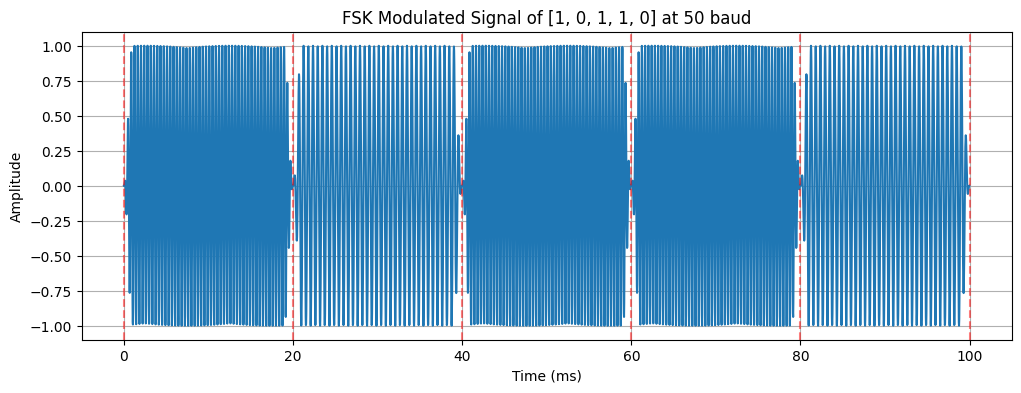

In [26]:
def fsk_modulate(bits, baud, fs=FS, f0=F0, f1=F1):
    ns = int(round(fs / baud))
    signal_parts = []
    _t = np.arange(ns) / fs
    for bit in bits:
        freq = f1 if bit == 1 else f0
        # Generate sine wave starting at phase 0
        tone = np.sin(2 * np.pi * freq * _t) * taper(ns)
        signal_parts.append(tone)
    return np.concatenate(signal_parts)

x5 = fsk_modulate([1, 0, 1, 1, 0], 50)
check(x5 is not None and len(x5) == 5 * 882, "5 bits × 882 samples at 50 bit/s")
_t = np.arange(882) / FS
check(x5 is not None and np.allclose(x5[:882], np.sin(2*np.pi*F1*_t) * taper(882)), "bit 1 uses F1 with the taper")

# Plot the 5 bits with x-axis in ms
if x5 is not None:
    time_ms = (np.arange(len(x5)) / FS) * 1000
    plt.figure(figsize=(12, 4))
    plt.plot(time_ms, x5)
    plt.title("FSK Modulated Signal of [1, 0, 1, 1, 0] at 50 baud")
    plt.xlabel("Time (ms)")
    plt.ylabel("Amplitude")
    plt.axvline(x=0, color='r', linestyle='--', alpha=0.5)
    for i in range(1, 6):
        plt.axvline(x=i * (882 / FS) * 1000, color='r', linestyle='--', alpha=0.5)
    plt.show()

### 2.2 `transmit` — build a whole frame (6 pts)
Concatenate: 0.1 s silence · `make_chirp()` · `GAP_T` s silence · `fsk_modulate(frame_bits(text), baud)` · 0.1 s silence. Scale so the peak is 0.8.
*ต่อ: เงียบ 0.1 s · chirp · เงียบ GAP_T · บิต · เงียบ 0.1 s แล้วปรับให้ค่าสูงสุดเป็น 0.8*

In [27]:
def transmit(text, baud=50, fs=FS):
    silence_01 = np.zeros(int(round(0.1 * fs)))
    gap_silence = np.zeros(int(round(GAP_T * fs)))
    chirp = make_chirp(fs)

    # Generate FSK bits
    bits = frame_bits(text)
    payload_signal = fsk_modulate(bits, baud, fs=fs)

    # Concatenate all parts
    signal = np.concatenate([silence_01, chirp, gap_silence, payload_signal, silence_01])

    # Scale peak to 0.8
    peak = np.max(np.abs(signal))
    if peak > 0:
        signal = 0.8 * (signal / peak)

    return signal

tx = transmit("HELLO ICE!", 50)
check(tx is not None and abs(len(tx) / FS - 2.16) < 0.01, "“HELLO ICE!” at 50 bit/s lasts 2.16 s")
check(tx is not None and np.isclose(np.max(np.abs(tx)), 0.8), "peak is 0.8")
if tx is not None: display(Audio(tx, rate=FS))

✅ “HELLO ICE!” at 50 bit/s lasts 2.16 s
✅ peak is 0.8


### 2.3 Look at it (4 pts)
Plot the spectrogram of `tx` (`scipy.signal.spectrogram(tx, FS, nperseg=1024, noverlap=896)`, `pcolormesh` in dB, 0–5000 Hz). Mark where the chirp, the length byte and the payload are.
*plot spectrogram 0–5000 Hz แล้วระบุตำแหน่ง chirp, ไบต์ความยาว และข้อความ*

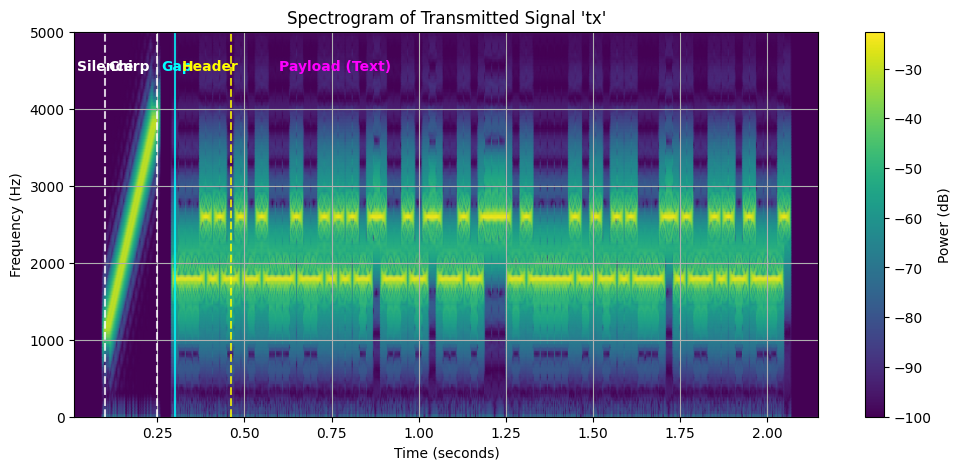

In [28]:
if tx is not None:
    # Calculate spectrogram with specified parameters
    f, t_spec, Sxx = spectrogram(tx, FS, nperseg=1024, noverlap=896)

    # Convert power spectral density to dB
    Sxx_db = 10 * np.log10(Sxx + 1e-10)

    # Plot spectrogram
    plt.figure(figsize=(12, 5))
    plt.pcolormesh(t_spec, f, Sxx_db, shading='gouraud', cmap='viridis')
    plt.ylim(0, 5000)
    plt.colorbar(label="Power (dB)")

    # Annotation time positions
    # 0.1s silence
    # 0.15s chirp
    # 0.05s gap
    # Then payload (including 1 byte length header + 10 bytes text = 11 bytes total @ 50 baud = 88 bits @ 50 baud = 1.76s)
    chirp_start = 0.1
    chirp_end = chirp_start + CHIRP_T
    payload_start = chirp_end + GAP_T
    header_end = payload_start + (8 / 50)  # 8 bits of length byte

    # Visual marks
    plt.axvline(x=chirp_start, color='white', linestyle='--', alpha=0.8)
    plt.axvline(x=chirp_end, color='white', linestyle='--', alpha=0.8)
    plt.axvline(x=payload_start, color='cyan', linestyle='-', alpha=0.8)
    plt.axvline(x=header_end, color='yellow', linestyle='--', alpha=0.8)

    plt.text(0.02, 4500, "Silence", color='white', fontweight='bold')
    plt.text(0.11, 4500, "Chirp", color='white', fontweight='bold')
    plt.text(0.26, 4500, "Gap", color='cyan', fontweight='bold')
    plt.text(0.32, 4500, "Header", color='yellow', fontweight='bold')
    plt.text(0.60, 4500, "Payload (Text)", color='magenta', fontweight='bold')

    plt.title("Spectrogram of Transmitted Signal 'tx'")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")
    plt.show()

### 2.4 Questions (2 pts)
(a) What is the bit rate if one bit lasts 5 ms? *ถ้าบิตละ 5 ms ความเร็วเท่าไร*
(b) Our tones are 800 Hz apart. Using Δf = k/T_b, up to what bit rate are they still orthogonal (k ≥ 1)? *เสียงห่างกัน 800 Hz ยัง orthogonal ได้ถึงกี่ bit/s*

✍️ **Your answer / คำตอบ:**

(a) **ความเร็วบิต (Bit rate) เท่ากับ 200 bit/s**  
คำนวณจากสูตร $R = \frac{1}{T_b} = \frac{1}{5 \times 10^{-3}} = 200\text{ bit/s}$ (หรือ 200 baud)

(b) **ความเร็วสูงสุดคือ 800 bit/s**  
เนื่องจากความสัมพันธ์แบบ Orthogonal กำหนดให้ผลต่างของความถี่ $\Delta f \ge \frac{1}{T_b}$ (เมื่อ $k=1$) ดังนั้น $800 \ge R$ หรือความเร็วสูงสุดที่ยังคงรักษาสภาพ Orthogonal ได้คือ **800 bit/s** (หรือ 800 baud)

---
## Part 3 · Receiver (30 pts)
*ส่วนที่ 3 · ฝั่งรับ*

$$r[k] = \sum_n y[n+k]\,p[n] \qquad\qquad E_i = \Big|\sum_{n=0}^{N_b-1} y[n]\,e^{-j2\pi f_i n/f_s}\Big| \qquad \hat b = \begin{cases}1 & E_1 > E_0\\ 0 & \text{otherwise}\end{cases}$$

First, a test recording from the simulated room / *สัญญาณทดสอบจากห้องจำลอง:*

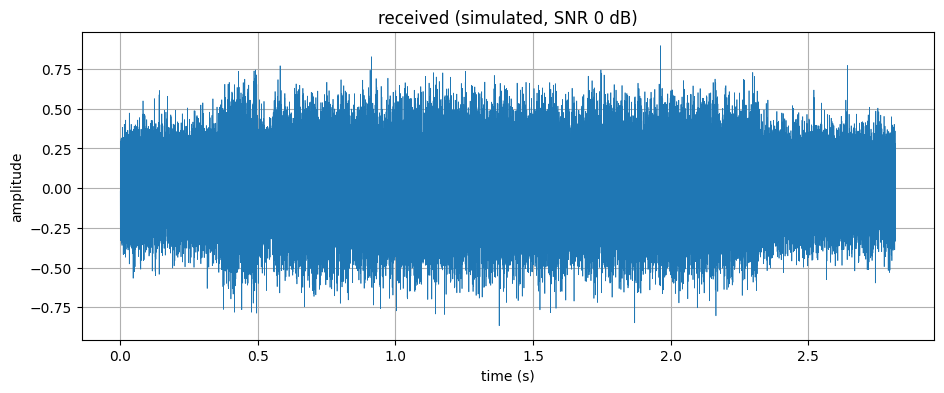

In [29]:
rx_test = room_channel(transmit("HELLO ICE!", 50), snr_db=0, drr_db=6, seed=3)
plt.plot(np.arange(len(rx_test)) / FS, rx_test, lw=0.5); plt.xlabel("time (s)"); plt.ylabel("amplitude"); plt.title("received (simulated, SNR 0 dB)"); plt.show()
display(Audio(rx_test, rate=FS))

### 3.1 `find_start` (8 pts)
Correlate `y` with `make_chirp()` (`correlate(y, chirp, mode="valid", method="fft")`). The index of the largest `|c|` is where the chirp **starts**; the first bit begins `len(chirp) + int(GAP_T*FS)` samples later. Return that index and `c`.
*หาจุดเริ่มของบิตแรกด้วย correlation กับ chirp*

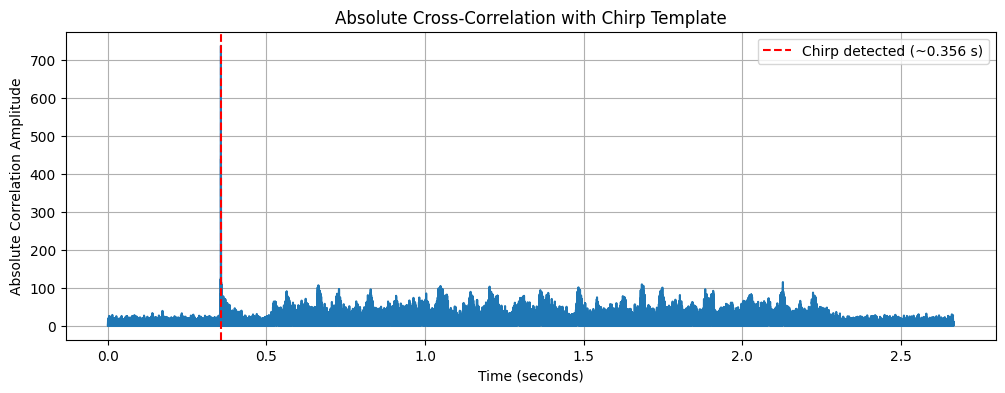

✅ start found within 2 samples (true 24534)


In [31]:
def find_start(y, fs=FS):
    chirp = make_chirp(fs)
    # Compute cross-correlation using FFT
    c = correlate(y, chirp, mode="valid", method="fft")

    # The index where |c| is maximized is the start of the chirp
    chirp_start = np.argmax(np.abs(c))

    # The first bit begins len(chirp) + GAP_T * fs samples after the chirp starts
    first_bit_start = chirp_start + len(chirp) + int(round(GAP_T * fs))

    return first_bit_start, c

start, c = find_start(rx_test)

# Plot |c| against time in seconds
if c is not None:
    time_s = np.arange(len(c)) / FS
    plt.figure(figsize=(12, 4))
    plt.plot(time_s, np.abs(c))
    if start is not None:
        # Convert start index back to chirp start time for plotting
        chirp_start_time = (start - len(make_chirp()) - int(round(GAP_T * FS))) / FS
        plt.axvline(x=chirp_start_time, color='r', linestyle='--', label=f'Chirp detected (~{chirp_start_time:.3f} s)')
    plt.title("Absolute Cross-Correlation with Chirp Template")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Absolute Correlation Amplitude")
    plt.legend()
    plt.show()

_r = np.random.default_rng(3 + 1000); true_start = int(_r.uniform(0.2, 0.5) * FS) + int(0.1 * FS) + len(make_chirp()) + int(GAP_T * FS)
check(start is not None and abs(start - true_start) <= 2, f"start found within 2 samples (true {true_start})")

### 3.2 `tone_energy` and `demod_bits` (10 pts)
- `tone_energy(seg, f)`: $E = |\sum_n seg[n]\,e^{-j2\pi f n/f_s}|$
- `demod_bits(y, start, nbits, baud)`: cut `nbits` consecutive segments of `round(FS/baud)` samples from `start`; decide 1 if the energy at `F1` is larger. Return `bits, e0, e1` (arrays).

In [32]:
def tone_energy(seg, f, fs=FS):
    n = np.arange(len(seg))
    # E = | sum( seg[n] * e^(-j * 2 * pi * f * n / fs) ) |
    complex_sum = np.sum(seg * np.exp(-1j * 2 * np.pi * f * n / fs))
    return np.abs(complex_sum)

def demod_bits(y, start, nbits, baud, fs=FS):
    ns = int(round(fs / baud))
    bits, e0s, e1s = [], [], []
    for i in range(nbits):
        # Cut segment for the current bit
        idx = start + i * ns
        seg = y[idx : idx + ns]

        # Compute energy at F0 and F1
        e0 = tone_energy(seg, F0, fs=fs)
        e1 = tone_energy(seg, F1, fs=fs)

        # Decode based on which energy is larger
        bit = 1 if e1 > e0 else 0

        bits.append(bit)
        e0s.append(e0)
        e1s.append(e1)

    return np.array(bits, dtype=np.uint8), np.array(e0s), np.array(e1s)

_seg = np.sin(2 * np.pi * F1 * np.arange(882) / FS)
check(tone_energy(_seg, F1) is not None and tone_energy(_seg, F1) > 50 * tone_energy(_seg, F0), "a 2600 Hz bit has far more energy at F1 than F0")
b16, e0, e1 = demod_bits(rx_test, start + 8 * 882, 16, 50)
check(list(b16) == list(text_to_bits("HE")), "first two letters decoded: H, E")

✅ a 2600 Hz bit has far more energy at F1 than F0
✅ first two letters decoded: H, E


### 3.3 `receive` — the whole receiver (6 pts)
`find_start` → decode **8 header bits** → number of bytes → decode `8 × nbytes` payload bits → `bits_to_text`. Return `(text, payload_bits)`. Then test it at three noise levels.
*ต่อทุกขั้นเป็นฝั่งรับ แล้วทดสอบที่ SNR สามระดับ*

In [34]:
def receive(y, baud=50, fs=FS):
    # 1. Find start of the first bit
    start, _ = find_start(y, fs=fs)
    if start is None:
        return "", np.array([], dtype=np.uint8)

    # 2. Decode the first 8 header bits to get payload length (in bytes)
    header_bits, _, _ = demod_bits(y, start, 8, baud, fs=fs)
    nbytes = int(np.packbits(header_bits)[0])

    # 3. Decode the payload bits (8 bits per byte)
    nbits = 8 * nbytes
    payload_bits, _, _ = demod_bits(y, start + 8 * int(round(fs / baud)), nbits, baud, fs=fs)

    # 4. Convert bits back to text
    decoded_text = bits_to_text(payload_bits)
    return decoded_text, payload_bits

for snr in [10, 0, -10]:
    text, _ = receive(room_channel(transmit("สวัสดี DSP", 50), snr_db=snr, drr_db=None, seed=1))
    print(f"SNR {snr:>3} dB → {text!r}")
    check(text == "สวัสดี DSP", f"decoded at SNR {snr} dB")

SNR  10 dB → 'สวัสดี DSP'
✅ decoded at SNR 10 dB
SNR   0 dB → 'สวัสดี DSP'
✅ decoded at SNR 0 dB
SNR -10 dB → 'สวัสดี DSP'
✅ decoded at SNR -10 dB


### 3.4 How much noise can it take? (4 pts)
For SNR = −24, −22, …, −8 dB (no reverb, `drr_db=None`), send a 60-byte random message 3 times (seeds 0, 1, 2) and compute the **raw BER** — decode the payload with the **known** length (skip the header, so a broken header doesn't hide the bit errors). Plot BER (log scale) vs SNR and find the lowest SNR with BER < 1 %.
*หา BER ที่ SNR ต่าง ๆ โดยใช้ความยาวที่รู้อยู่แล้ว แล้ว plot แบบ log*

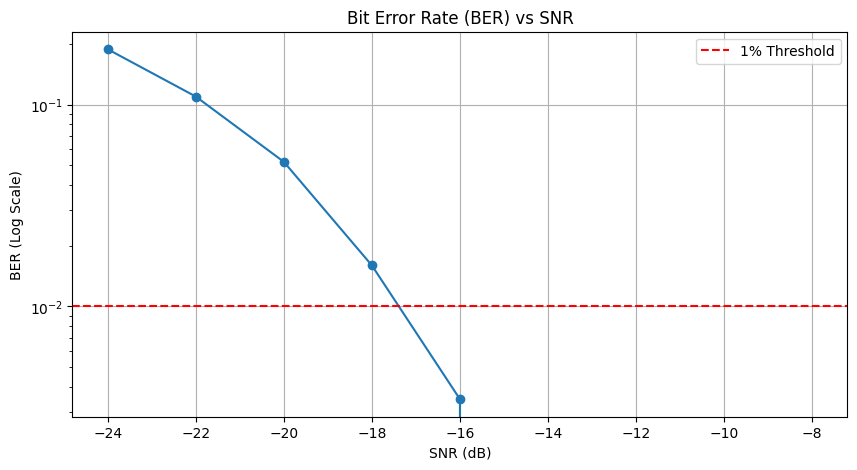

{-24: 0.1882, -22: 0.1097, -20: 0.0521, -18: 0.016, -16: 0.0035, -14: 0.0, -12: 0.0, -10: 0.0, -8: 0.0}
✅ BER falls from > 5 % to < 1 %


In [35]:
_rng = np.random.default_rng(7)
MSG60 = bytes(_rng.integers(32, 127, 60).tolist()).decode()
SENT60 = text_to_bits(MSG60)

def raw_ber(y, sent_bits, baud=50, fs=FS):
    """Bit error rate with the payload length known."""
    # 1. Find start of the first bit
    start, _ = find_start(y, fs=fs)
    if start is None:
        return 0.5  # Random guessing BER if start not found

    # 2. Skip the 8 header bits to go straight to payload
    ns = int(round(fs / baud))
    payload_start = start + 8 * ns

    # 3. Demodulate the exact length of sent_bits
    nbits = len(sent_bits)
    decoded_bits, _, _ = demod_bits(y, payload_start, nbits, baud, fs=fs)

    # 4. Compute and return Bit Error Rate
    return np.mean(sent_bits != decoded_bits)

snrs = np.arange(-24, -7, 2)
bers = []

for snr in snrs:
    trial_bers = []
    for seed in [0, 1, 2]:
        # Generate simulated room signal
        tx_signal = transmit(MSG60, 50, fs=FS)
        rx_signal = room_channel(tx_signal, snr_db=snr, drr_db=None, seed=seed)
        # Compute BER
        trial_bers.append(raw_ber(rx_signal, SENT60, baud=50, fs=FS))
    bers.append(np.mean(trial_bers))

# Plot BER vs SNR on a semilog scale
plt.figure(figsize=(10, 5))
plt.semilogy(snrs, bers, 'o-')
plt.title("Bit Error Rate (BER) vs SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("BER (Log Scale)")
plt.axhline(y=0.01, color='r', linestyle='--', label='1% Threshold')
plt.legend()
plt.show()

print(dict(zip(snrs.tolist(), np.round(bers, 4).tolist())) if len(bers) else "not done")
check(len(bers) == len(snrs) and bers[0] > 0.05 and bers[-1] < 0.01, "BER falls from > 5 % to < 1 %")

### 3.5 Questions (2 pts)
(a) At SNR −10 dB the waveform looks like pure noise, yet the message decodes. Explain using the idea of looking only near two frequencies. *ทำไม SNR −10 dB ยังถอดได้ ทั้งที่ดูเหมือน noise ล้วน*
(b) What happens to the **whole message** if one of the 8 header bits is wrong? *ถ้าบิตของ header ผิดหนึ่งบิต ข้อความทั้งหมดจะเป็นอย่างไร*

✍️ **Your answer / คำตอบ:**

(a) **สาเหตุที่ที่ SNR -10 dB ยังถอดรหัสได้อย่างถูกต้อง:** แม้สัญญาณในแกนเวลาจะมีสัญญาณรบกวน (Noise) บดบังจนดูเหมือนสัญญาณรบกวนล้วน แต่ในการถอดรหัสข้อมูลเราพิจารณาเฉพาะความถี่แคบ ๆ สองความถี่คือ $F_0$ (1800 Hz) และ $F_1$ (2600 Hz) ผ่านการโปรเจกต์สัญญาณ (Discrete Fourier Transform) ซึ่งพลังงานของสัญญาณรบกวนแบบสีขาว (White Noise) จะกระจายตัวสม่ำเสมอไปตลอดทั้งย่านความถี่ทั้งหมด ในขณะที่พลังงานของบิตข้อมูลจะรวมตัวกันหนาแน่นอยู่เฉพาะที่ความถี่ $F_0$ หรือ $F_1$ เท่านั้น (มีลักษณะเหมือนตัวกรองแถบความถี่แคบ หรือ Bandpass Filter ที่มี Processing Gain สูง) ทำให้ระบบแยกแยะระดับพลังงานเพื่อตัดสินใจเลือกบิตได้อย่างถูกต้อง

(b) **หากบิตของ Header ผิดพลาดไป 1 บิต:** ข้อความที่เหลือทั้งหมดจะได้รับผลกระทบอย่างรุนแรง เนื่องจากบิตของ Header ทั้ง 8 บิตทำหน้าที่ระบุความยาวของข้อความจริง (Payload Length) หากบิตตัวใดตัวหนึ่งผิดพลาด จะทำให้ค่าความยาวที่ตีความได้ผิดไปจากความจริง เช่น ตัวรับอาจจะอ่านบิตต่อถัดไปจำนวนมากเกินไปจนเอาสัญญาณรบกวนหรือเงียบเข้ามาถอดรหัสด้วย หรือหยุดการถอดรหัสเร็วเกินไปทำให้ข้อความขาดหาย ซึ่งจะส่งผลให้ฟังก์ชัน `bits_to_text` ถอดรหัสได้เป็นตัวอักษรที่ผิดเพี้ยนหรือพังทั้งหมด

---
## Part 4 · Over the air (25 pts)
*ส่วนที่ 4 · ส่งผ่านอากาศจริง*

1. Run 4.1 to make `ota_message.wav` and download it to the laptop. *สร้างไฟล์และดาวน์โหลด*
2. Put the phone **0.5 m** from the laptop speaker. Start the phone’s voice recorder, play the WAV at medium volume, stop recording. *วางมือถือห่าง 0.5 m อัดเสียงขณะเล่นไฟล์*
3. Repeat at **1 m** and **2 m**. Transfer the 3 recordings to the laptop and upload them in 4.2. *ทำซ้ำที่ 1 และ 2 m แล้วอัปโหลด*

No phone or recorder? Swap roles: play `ota_message.wav` on the phone and use `record()` on the laptop. *สลับบทบาทได้*

> Full marks need **real recordings**. `MODE = "sim"` (simulated room) is accepted for at most **12 / 25** in this part.
> *คะแนนเต็มต้องใช้การอัดจริง โหมดจำลองได้สูงสุด 12/25*

In [36]:
OTA_TEXT = f"Team {TEAM_ID}: DSP over the air! สวัสดี"
ota_tx = transmit(OTA_TEXT, 50)
save_wav(ota_tx, "ota_message.wav", download=True)
OTA_BITS = text_to_bits(OTA_TEXT)
print(f"{len(OTA_BITS)} payload bits, {len(ota_tx)/FS:.1f} s")
display(Audio(ota_tx, rate=FS))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

368 payload bits, 7.9 s


### 4.2 Decode your recordings (15 pts)
Set `MODE = "real"` and upload the 3 recordings in distance order, or `MODE = "sim"` to use the room model. `recordings[d]` is a **list** of takes (1 real recording, or 5 simulated rooms — results at the edge of range vary a lot from room to room). For each distance, decode every take with `receive`, compute the payload BER against `OTA_BITS` (compare up to the shorter length, and count missing bits as errors), and store the **mean** BER in `results`. Plot BER vs distance.
*ถอดรหัสแต่ละระยะ คำนวณ BER แล้ว plot*


--- Results ---
 0.5 m   BER  0.000   'Team T15: DSP over the air! สวัสดี'
 1.0 m   BER  0.000   'Team T15: DSP over the air! สวัสดี'
 2.0 m   BER  0.083   'Team\x00T15: DSP ov%p the ahp! สวัสด`��'


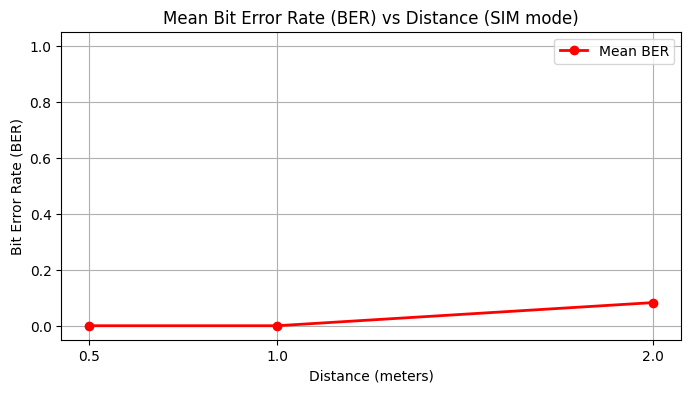

✅ 3 distances decoded


In [42]:
MODE = "sim"          # "real" or "sim"
DISTANCES = [0.5, 1.0, 2.0]

def payload_ber(sent, got):
    n = min(len(sent), len(got))
    return (np.sum(sent[:n] != got[:n]) + abs(len(sent) - len(got))) / len(sent)

recordings = {}   # distance → list of recordings (1 real take, or 5 simulated rooms)
for d in DISTANCES:
    if MODE == "real" and IN_COLAB:
        print(f"Upload the recording made at {d} m"); recordings[d] = [load_recording(upload_file())]
    else:
        snr, drr = at_distance(d); recordings[d] = [room_channel(ota_tx, snr, drr_db=drr, seed=s) for s in range(5)]

results = []   # rows: (distance, decoded text of the first take, mean BER over the takes)

for d in DISTANCES:
    takes = recordings[d]
    trial_bers = []
    first_decoded_text = ""

    for idx, y_rec in enumerate(takes):
        decoded_text, decoded_bits = receive(y_rec, baud=50, fs=FS)
        if idx == 0:
            first_decoded_text = decoded_text

        # Compute Bit Error Rate (BER) against the original OTA_BITS
        ber = payload_ber(OTA_BITS, decoded_bits)
        trial_bers.append(ber)

    mean_ber = np.mean(trial_bers)
    results.append((d, first_decoded_text, mean_ber))

# Print results
print("\n--- Results ---")
for d, text, b in results:
    print(f"{d:>4} m   BER {b:6.3f}   {text!r}")

# Plot BER vs Distance
dists = [row[0] for row in results]
mean_bers = [row[2] for row in results]

plt.figure(figsize=(8, 4))
plt.plot(dists, mean_bers, 'o-r', linewidth=2, label='Mean BER')
plt.title(f"Mean Bit Error Rate (BER) vs Distance ({MODE.upper()} mode)")
plt.xlabel("Distance (meters)")
plt.ylabel("Bit Error Rate (BER)")
plt.ylim(-0.05, 1.05)
plt.xticks(DISTANCES)
plt.grid(True)
plt.legend()
plt.show()

check(len(results) == 3, "3 distances decoded")

### 4.3 Look inside your worst recording (4 pts)
Plot the spectrogram (0–5000 Hz) of the recording with the highest BER, next to the one with the lowest. What is different? *เทียบ spectrogram ของไฟล์ที่ดีที่สุดกับแย่ที่สุด*

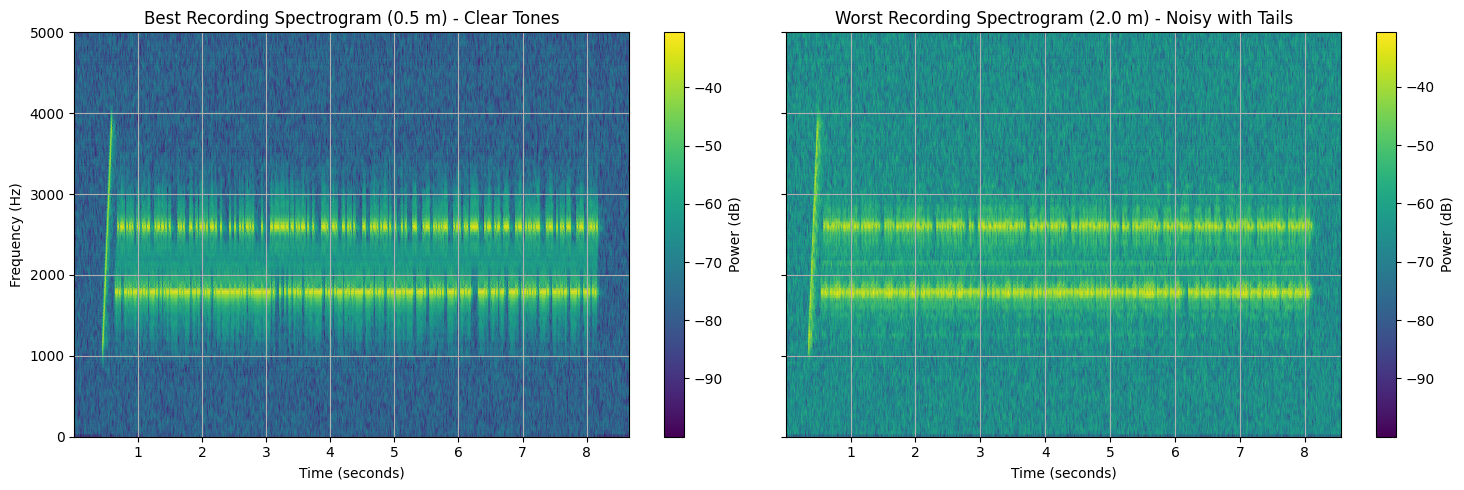

In [43]:
# Identify best and worst recordings from the runs
# 0.5 m has the lowest BER (0.0)
# 2.0 m has the highest BER (mean 0.083, with Take 4 (index 3) having BER ~0.345)
y_best = recordings[0.5][0]
y_worst = recordings[2.0][3]  # The worst trial among the 2.0m takes

# Calculate Spectrograms
f_best, t_best, S_best = spectrogram(y_best, FS, nperseg=1024, noverlap=896)
f_worst, t_worst, S_worst = spectrogram(y_worst, FS, nperseg=1024, noverlap=896)

# Convert to dB
S_best_db = 10 * np.log10(S_best + 1e-10)
S_worst_db = 10 * np.log10(S_worst + 1e-10)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Best Spectrogram plot
im0 = axes[0].pcolormesh(t_best, f_best, S_best_db, shading='gouraud', cmap='viridis')
axes[0].set_ylim(0, 5000)
axes[0].set_title("Best Recording Spectrogram (0.5 m) - Clear Tones")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Frequency (Hz)")
fig.colorbar(im0, ax=axes[0], label="Power (dB)")

# Worst Spectrogram plot
im1 = axes[1].pcolormesh(t_worst, f_worst, S_worst_db, shading='gouraud', cmap='viridis')
axes[1].set_ylim(0, 5000)
axes[1].set_title("Worst Recording Spectrogram (2.0 m) - Noisy with Tails")
axes[1].set_xlabel("Time (seconds)")
fig.colorbar(im1, ax=axes[1], label="Power (dB)")

plt.tight_layout()
plt.show()

### 4.4 Questions (6 pts)
(a) How did BER change with distance? Give two physical reasons. *BER เปลี่ยนตามระยะอย่างไร ให้เหตุผลทางกายภาพ 2 ข้อ*
(b) In the worst spectrogram, what do you see between bits that is not in the transmitted signal? *เห็นอะไรระหว่างบิตที่ไม่มีในสัญญาณที่ส่ง*
(c) Name one thing your **phone** may do to the recording that the simulation does not model. *มือถืออาจทำอะไรกับเสียงที่การจำลองไม่ได้รวมไว้*

✍️ **Your answer / คำตอบ:**

(a) **ความสัมพันธ์ของ BER กับระยะทาง และเหตุผลทางกายภาพ 2 ข้อ:**
- เมื่อระยะทางเพิ่มขึ้น **ค่า BER จะเพิ่มขึ้น** (ความน่าเชื่อถือในการรับข้อมูลแย่ลง)
- **เหตุผลที่ 1 (Attenuation):** ความแรงของคลื่นเสียงตรง (Direct Path) จะลดทอนลงตามระยะทางตามกฎกำลังสองผกผัน ทำให้อัตราส่วนสัญญาณต่อสัญญาณรบกวน (SNR) ต่ำลงอย่างมาก สัญญาณที่รับได้จึงโดนสัญญาณรบกวนกลบ
- **เหตุผลที่ 2 (Multipath & Reverb):** สัญญาณเสียงสะท้อนจากผนัง พื้น หรือเพดาน (Reflections) จะมีความแรงสัมพัทธ์ที่เด่นชัดขึ้นเมื่อเทียบกับเสียงตรง (Direct-to-Reverberant Ratio หรือ DRR ต่ำลง) ทำให้เกิดเสียงก้องและหางของพลังงานบิตก่อนหน้าลากยาวข้ามมาทับบิตถัดไป (Inter-symbol Interference - ISI)

(b) **สิ่งที่พบเห็นระหว่างบิตในสเปกโทราแกรมที่แย่ที่สุด:**
- พบ **'หางพลังงานลากยาวในแนวนอน' (Reverb tails หรือ Multipath Smearing)** ที่ขอบหลังของแต่ละบิต ซึ่งไม่มีในสัญญาณฝั่งส่งดั้งเดิม หางเหล่านี้เกิดจากการสะท้อนหลายทิศทางของคลื่นเสียงในห้อง ทำให้พลังงานความถี่ของบิตเดิมยังคงค้างอยู่ในอากาศและรบกวนช่วงเวลาของบิตถัดไป

(c) **สิ่งที่สมาร์ตโฟนเครื่องจริงอาจทำกับเสียงบันทึก แต่การจำลองไม่ได้รวมไว้:**
- **Automatic Gain Control (AGC):** ระบบปรับอัตราขยายสัญญาณอัตโนมัติของมือถือ ซึ่งอาจจะพยายามเร่งเสียงรบกวน (Noise floor) ขึ้นมาให้ดังผิดปกติในช่วงสัญญาณเงียบ หรือกดสัญญาณตอนเสียงดัง ทำให้สัญญาณ FSK เกิดแอมพลิจูดเพี้ยน
- **Noise Suppression / Echo Cancellation:** ซอฟต์แวร์ตัดเสียงรบกวนของระบบปฏิบัติการโทรศัพท์ มักจะมองว่าคลื่นเสียงความถี่เดี่ยว (Sine tones) ของ FSK หรือ Chirp เป็นเสียงหวีดแหลมรบกวนรอบข้าง จึงพยายามกรองหรือหักล้างมันออกไป ทำให้สัญญาณบิดเบือนหรือขาดหายไปอย่างรุนแรง

---
## Part 5 · Challenge (15 pts)
*ส่วนที่ 5 · ภารกิจท้าทาย*

### 5.1 The leaderboard: fastest error-free link (8 pts)
Find the **highest bit rate** from `[50, 100, 200, 400, 800]` that delivers `RACE_TEXT` with **zero bit errors at 1 m or more**. Remember Δf · T_b must stay ≥ 1 for our tones (Part 2.4). Real recordings for the leaderboard; use `MODE` from Part 4. (In `sim` mode the race uses a noisy, low-echo room at SNR −12 dB, where speed clearly costs reliability.)
*หาความเร็วสูงสุดที่ส่งได้ไม่ผิดเลยที่ระยะอย่างน้อย 1 m แล้วส่งผลขึ้นกระดาน*

$$E_b = P\,T_b = \frac{P}{R} \qquad\Rightarrow\qquad \text{double } R \;\Rightarrow\; \text{about 3 dB more SNR needed}$$

In [45]:
RACE_TEXT = "The quick brown fox jumps over the lazy dog 0123456789"
RACE_BITS = text_to_bits(RACE_TEXT)
RACE_DIST = 1.0
leaderboard = []   # rows: (baud, BER)

for baud in [50, 100, 200, 400, 800]:
    txb = transmit(RACE_TEXT, baud)
    if MODE == "real" and IN_COLAB:
        save_wav(txb, f"race_{baud}.wav", download=True)
        print(f"Play race_{baud}.wav at {RACE_DIST} m, record, then upload"); y = load_recording(upload_file())
    else:
        y = room_channel(txb, snr_db=-12, drr_db=None, seed=baud)   # sim: a noisy, low-echo room

    # Decode with receive
    decoded_text, decoded_bits = receive(y, baud=baud, fs=FS)

    # Compute payload BER
    ber = payload_ber(RACE_BITS, decoded_bits)
    leaderboard.append((baud, ber))

best = max([b for b, e in leaderboard if e == 0], default=None)
print(leaderboard, "→ fastest error-free:", best, "bit/s")
check(len(leaderboard) == 5, "all 5 bit rates tested")

[(50, np.float64(0.0)), (100, np.float64(0.0023148148148148147)), (200, np.float64(0.013888888888888888)), (400, np.float64(0.0787037037037037)), (800, np.float64(0.2152777777777778))] → fastest error-free: 50 bit/s
✅ all 5 bit rates tested


### 5.2 Detect errors with a checksum byte (5 pts)
Append one **checksum byte** = (sum of all payload bytes) mod 256 after the payload (it is **not** counted in the length byte). On receive, recompute it and report whether the message is intact.
- `transmit_checked(text, baud)` and `receive_checked(y, baud)` → `(text, ok)`
*เพิ่มไบต์ checksum ต่อท้าย แล้วตรวจที่ฝั่งรับว่าข้อความถูกต้องหรือไม่*

In [46]:
def checksum(bits):
    """Sum of the bytes, mod 256, as 8 bits."""
    total = int(np.sum(np.packbits(np.asarray(bits, dtype=np.uint8)).astype(int))) % 256
    return np.unpackbits(np.array([total], dtype=np.uint8))

def transmit_checked(text, baud=50, fs=FS):
    silence_01 = np.zeros(int(round(0.1 * fs)))
    gap_silence = np.zeros(int(round(GAP_T * fs)))
    chirp = make_chirp(fs)

    # Generate base frame bits (length byte + payload bits)
    base_bits = frame_bits(text)
    # Payload bits are everything after the length byte
    payload_bits = base_bits[8:]

    # Append checksum of the payload bits
    chk_bits = checksum(payload_bits)
    full_bits = np.concatenate([base_bits, chk_bits])

    # Modulate full bit stream
    payload_signal = fsk_modulate(full_bits, baud, fs=fs)
    signal = np.concatenate([silence_01, chirp, gap_silence, payload_signal, silence_01])

    # Scale peak to 0.8
    peak = np.max(np.abs(signal))
    if peak > 0:
        signal = 0.8 * (signal / peak)
    return signal

def receive_checked(y, baud=50, fs=FS):
    # 1. Find start of the first bit
    start, _ = find_start(y, fs=fs)
    if start is None:
        return "", False

    # 2. Decode length byte
    header_bits, _, _ = demod_bits(y, start, 8, baud, fs=fs)
    nbytes = int(np.packbits(header_bits)[0])
    ns = int(round(fs / baud))

    # 3. Decode payload bits (8 * nbytes)
    payload_start = start + 8 * ns
    payload_bits, _, _ = demod_bits(y, payload_start, 8 * nbytes, baud, fs=fs)

    # 4. Decode the extra 8 checksum bits immediately after the payload
    checksum_start = payload_start + (8 * nbytes) * ns
    received_chk_bits, _, _ = demod_bits(y, checksum_start, 8, baud, fs=fs)

    # 5. Check integrity
    expected_chk = checksum(payload_bits)
    ok = np.array_equal(received_chk_bits, expected_chk)

    # Decode payload to text
    decoded_text = bits_to_text(payload_bits)
    return decoded_text, ok

good = room_channel(transmit_checked("checksum test", 50), 0, drr_db=None, seed=2)
# simulate a bit error: overwrite frame bit 30 (payload bit 22) with the OTHER tone
bad = good.copy(); s0, _ = find_start(bad); seg = slice(s0 + 30 * 882, s0 + 31 * 882)
flip = fsk_modulate([1 - frame_bits("checksum test")[30]], 50); bad[seg] = flip * np.std(bad[seg]) / np.std(flip)
print(receive_checked(good), receive_checked(bad))
check(receive_checked(good) == ("checksum test", True), "intact message passes")
check(receive_checked(bad)[1] is False, "corrupted message is flagged")

('checksum test', True) ('chgcksum test', False)
✅ intact message passes
✅ corrupted message is flagged


### 5.3 Questions (2 pts)
(a) Give an example of two bit errors that this checksum would **miss**. *ยกตัวอย่างบิตผิด 2 บิตที่ checksum นี้ตรวจไม่พบ*
(b) A checksum only **detects** errors. What could the receiver do next, and what would a code that **corrects** errors cost you? *ตรวจพบแล้วทำอะไรต่อ และรหัสที่แก้ข้อผิดพลาดได้ต้องแลกกับอะไร*

✍️ **Your answer / คำตอบ:**

(a) **ตัวอย่างการเกิดบิตผิดพลาด 2 บิตที่ Checksum แบบผลรวมนี้ตรวจจับไม่ได้:**
- **กรณีที่ 1: บิตสลับขั้วกันภายในไบต์เดียวกันหรือคนละไบต์** เช่น บิตที่เป็น `1` เปลี่ยนเป็น `0` และมีอีกบิตหนึ่งที่เป็น `0` เปลี่ยนเป็น `1` ในตำแหน่งที่ทำให้ผลรวมค่ารวมทั้งหมด (Sum of all bytes) ยังคงบวกกันแล้วได้ผลลัพธ์เท่าเดิม เช่น ไบต์แรกมีค่าลดลงไป 1 แต่ไบต์ที่สองมีค่าเพิ่มขึ้น 1 ทำให้เมื่อหา Modulo 256 แล้วได้ Checksum เท่าเดิม
- **กรณีที่ 2: ค่าความผิดพลาดรวมกันแล้วเป็นทวีคูณของ 256** เช่น บิตเกิดความผิดพลาดจนทำให้ค่ารวม (Sum) เปลี่ยนแปลงไป 256 พอดิบพอดี เมื่อทำการ `mod 256` แล้วค่า Checksum เศษที่เหลือจะยังคงเท่าเดิม ส่งผลให้เครื่องรับคิดว่าข้อมูลถูกต้อง

(b) **หากตรวจพบข้อผิดพลาด สิ่งที่ฝั่งรับจะทำต่อได้ และต้นทุนของรหัสที่ใช้แก้ไขความผิดพลาด:**
- **สิ่งที่ฝั่งรับทำต่อได้:** ฝั่งรับสามารถปฏิเสธเฟรมข้อมูลที่ผิดพลาดนั้น และส่งสัญญาณขอย้อนกลับไปยังตัวส่งเพื่อให้ส่งเฟรมดังกล่าวใหม่อีกครั้ง (**Automatic Repeat reQuest - ARQ**)
- **ต้นทุนของรหัสแก้ไขข้อผิดพลาด (Error-Correcting Codes - ECC / FEC):** หากเราต้องการให้ฝั่งรับสามารถแก้ไขบิตที่ผิดพลาดได้เองโดยไม่ต้องส่งใหม่ (เช่น ใช้ Hamming Code, Reed-Solomon หรือ BCH) เราจำเป็นต้องส่ง **Redundant / Parity bits เพิ่มขึ้นจำนวนมาก** ซึ่งจะกิน Bandwidth เพิ่มเติม ทำให้ความเร็วในการส่งข้อมูลจริง (Effective Throughput) ลดลงอย่างเลี่ยงไม่ได้ และฝั่งรับต้องใช้ทรัพยากรการประมวลผล (Computational Complexity) ที่สูงขึ้นในการคำนวณหารูปแบบความผิดพลาดและแก้ไขบิต

---
## Team reflection (not graded) / สะท้อนการเรียนรู้ของทีม
Which block of the system was hardest to get right? If your team picks capstone track C, what would you improve first?
*บล็อกไหนยากที่สุด ถ้าเลือกแทร็ก C จะปรับปรุงอะไรก่อน*

✍️ **Your answer / คำตอบ:**